# Build a Simple Language Model: Don Quijote de la Mancha

Train a **character-level language model from scratch** on Miguel de Cervantes's Spanish novel. Given preceding characters, the model predicts the next character; repeating this operation generates new text.

We first train a **bigram baseline** (one character of context), then a **small decoder-only Transformer** (up to 64 characters of context). This is a teaching model, so expect spelling patterns and short word-like sequences before coherent prose.

References supplied for this assignment:
- [Karpathy_GPT_Teaching_Edition.ipynb](Karpathy_GPT_Teaching_Edition.ipynb): tokenization, batches, bigram model, GPT blocks, and training.
- [Self_Attention_Sebastian_CH3.ipynb](Self_Attention_Sebastian_CH3.ipynb): trainable queries/keys/values, scaled dot-product attention, causal masking, and multiple heads.
- Corpus: [Project Gutenberg, ebook 2000](https://www.gutenberg.org/ebooks/2000), [UTF-8 text](https://www.gutenberg.org/files/2000/2000-0.txt).

**Run:** use Python 3 with PyTorch and Matplotlib, then run all cells in order. The corpus is reused if already present. Training time depends on your hardware; reduce `max_iters` for a quick demonstration. All reported losses and samples below come from executing the code, not assumed results.


## 1. Setup and experiment settings

If dependencies are missing, run the commented installation cell once and restart the kernel. CPU, CUDA, and Apple Silicon MPS are supported. Seeds improve repeatability, but different devices can produce different results.


In [3]:
# Uncomment if needed, then restart the kernel:
%pip install torch matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.6/138.6 MB 14.4 MB/s  0:00:09m0:00:0100:01
Note: you may need to restart the kernel to use updated packages.


In [4]:
from pathlib import Path
import hashlib
import math
import time
import unicodedata
import urllib.request

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

SEED = 1337
torch.manual_seed(SEED)
# A few CPU threads are often faster than many threads for a model this small.
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device(
    'cuda' if torch.cuda.is_available() else
    'mps' if torch.backends.mps.is_available() else 'cpu'
)

config = {
    'block_size': 64,       # maximum preceding characters available to the GPT
    'batch_size': 32,       # independent sequences per training update
    'n_embd': 64,           # token/position embedding dimension
    'n_head': 4,            # each head has dimension 64 / 4 = 16
    'n_layer': 2,
    'dropout': 0.1,
    'learning_rate': 1e-3,
    'max_iters': 1500,
    'eval_interval': 250,
    'eval_iters': 20,
    'bigram_iters': 1000,
}
assert config['n_embd'] % config['n_head'] == 0
# Resolve paths whether the kernel starts in Week 4 or the project root.
work_dir = Path.cwd()
if (work_dir / 'Week 4' / 'Assignment4.ipynb').exists():
    work_dir = work_dir / 'Week 4'
output_dir = work_dir / 'don_quijote_outputs'
output_dir.mkdir(exist_ok=True)
print('PyTorch:', torch.__version__)
print('Device:', device)
print('Working directory:', work_dir)
print(config)


PyTorch: 2.15.0
Device: mps
Working directory: /Users/sovinbirla/UChicago/Generative AI/Week 4
{'block_size': 64, 'batch_size': 32, 'n_embd': 64, 'n_head': 4, 'n_layer': 2, 'dropout': 0.1, 'learning_rate': 0.001, 'max_iters': 1500, 'eval_interval': 250, 'eval_iters': 20, 'bigram_iters': 1000}


## 2. Download and clean the Spanish corpus

The requested shell command is:
```bash
wget https://www.gutenberg.org/files/2000/2000-0.txt -O don_quijote.txt
```
The next cell uses Python's standard library for the same download, including on systems without `wget`. We retain the original file, remove the Gutenberg header/footer from the training text, and preserve accents, capitalization, punctuation, and paragraph breaks. The book's front matter and table of contents remain part of the corpus.


In [3]:
CORPUS_URL = 'https://www.gutenberg.org/files/2000/2000-0.txt'
corpus_path = work_dir / 'don_quijote.txt'
if not corpus_path.exists():
    request = urllib.request.Request(CORPUS_URL, headers={'User-Agent': 'DonQuijoteTeachingNotebook/1.0'})
    with urllib.request.urlopen(request, timeout=60) as response:
        downloaded = response.read()
    corpus_path.write_bytes(downloaded)

raw_text = corpus_path.read_text(encoding='utf-8-sig')
start_marker = '*** START OF THE PROJECT GUTENBERG EBOOK DON QUIJOTE ***'
end_marker = '*** END OF THE PROJECT GUTENBERG EBOOK DON QUIJOTE ***'
if start_marker not in raw_text or end_marker not in raw_text:
    raise ValueError('Expected Gutenberg markers are missing; inspect the downloaded file.')
text = raw_text.split(start_marker, 1)[1].split(end_marker, 1)[0]
text = unicodedata.normalize('NFC', text).strip()
corpus_sha256 = hashlib.sha256(corpus_path.read_bytes()).hexdigest()
assert len(text) > 100_000, 'The downloaded corpus looks incomplete.'
print(f'Raw characters: {len(raw_text):,}; training-corpus characters: {len(text):,}')
print('Corpus SHA-256:', corpus_sha256)
print('\nPreview:\n' + text[:600])


Raw characters: 2,130,397; training-corpus characters: 2,110,726
Corpus SHA-256: 392270e534c66988d6e949ba0f9a64117969fde0f2aebbc6efef3314e23e4385

Preview:
El ingenioso hidalgo don Quijote de la Mancha



por Miguel de Cervantes Saavedra





El ingenioso hidalgo don Quijote de la Mancha


  
Tasa

  
Testimonio de las erratas

  
El Rey

  
Al Duque de Béjar

  
Prólogo

  
Al libro de don Quijote de la Mancha



Que trata de la condición y ejercicio del famoso
hidalgo don Quijote de la Mancha

Que trata de la primera salida que de su tierra hizo
el ingenioso don Quijote

Donde se cuenta la graciosa manera que tuvo don
Quijote en armarse caballero

De lo que le sucedió a nuestro caballero cuando salió
de la venta

Donde se prosigue la narración 


## 3. Character tokenization and a contiguous split

Each distinct character gets an integer ID. For example, `ñ` and `n` are different tokens. A character tokenizer needs no pretrained tokenizer or API.

Use the first 90% of the text for training and the final 10% for validation **before sampling windows**. This prevents overlapping training and validation windows. We enumerate the character set from the full corpus so every validation character has an ID; this reveals the alphabet, but no validation sequences are used in gradient updates. Validation is for model comparison, not an independent final test set.


In [4]:
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

def encode(s):
    s = unicodedata.normalize('NFC', s)
    unknown = sorted(set(s) - set(stoi))
    if unknown:
        raise ValueError(f'Characters outside the corpus vocabulary: {unknown!r}')
    return [stoi[ch] for ch in s]

def decode(ids):
    return ''.join(itos[int(i)] for i in ids)

example = 'En un lugar de la Mancha'
assert decode(encode(example)) == example
print(f'Vocabulary size: {vocab_size}')
print('Characters:', repr(''.join(chars)))
print('Example IDs:', encode(example))
print('Round trip:', decode(encode(example)))

data = torch.tensor(encode(text), dtype=torch.long)  # stays on CPU; move batches to device
split_at = int(0.9 * len(data))
splits = {'train': data[:split_at], 'val': data[split_at:]}
assert all(len(part) > config['block_size'] for part in splits.values())
print(f"Training: {len(splits['train']):,}; validation: {len(splits['val']):,} characters")


Vocabulary size: 92
Characters: '\n !"\'(),-.01234567:;?ABCDEFGHIJLMNOPQRSTUVWXYZ]abcdefghijlmnopqrstuvxyz¡«»¿ÁÉÍÑÓÚàáéíïñóùúü—'
Example IDs: [25, 59, 1, 66, 59, 1, 57, 66, 53, 47, 63, 1, 50, 51, 1, 57, 47, 1, 32, 47, 59, 49, 54, 47]
Round trip: En un lugar de la Mancha
Training: 1,899,653; validation: 211,073 characters


## 4. Preparing data inputs and targets

For a window `En un`, inputs are `En u` and targets are `n un`: every target is shifted one character to the right. An input tensor has shape `(B, T)`, where `B` is batch size and `T` is context length. The model predicts all `B × T` next characters in one forward pass. The examples within a window share context; they are not statistically independent.


In [5]:
def get_batch(split, generator=None):
    part = splits[split]
    T = config['block_size']
    starts = torch.randint(len(part) - T, (config['batch_size'],), generator=generator)
    positions = starts[:, None] + torch.arange(T)[None, :]
    x = part[positions].to(device)
    y = part[positions + 1].to(device)
    return x, y

xb, yb = get_batch('train')
assert torch.equal(xb[:, 1:], yb[:, :-1])
print('Input / target shapes:', tuple(xb.shape), tuple(yb.shape))
print('Input: ', repr(decode(xb[0].tolist())))
print('Target:', repr(decode(yb[0].tolist())))
print(f'Uniform-prediction cross-entropy: ln({vocab_size}) = {math.log(vocab_size):.4f}')


Input / target shapes: (32, 64) (32, 64)
Input:  'hásemos en tierra a su padre y a todos los\ndemás moros que allí '
Target: 'ásemos en tierra a su padre y a todos los\ndemás moros que allí a'
Uniform-prediction cross-entropy: ln(92) = 4.5218


## 5. A bigram baseline and shared training functions

The bigram model stores a row of next-character scores for each current character. It can learn transitions such as `q → u`, but it cannot use earlier characters to distinguish longer contexts. It has `vocab_size²` parameters.

Cross-entropy measures next-character prediction error in natural-log units (nats). Lower is better. Perplexity is `exp(loss)`; compare it only when tokenization and evaluation data match. A **uniform** predictor has loss `ln(vocab_size)`; random nonuniform logits need not achieve that value.


In [6]:
class BigramLanguageModel(nn.Module):
    context_length = 1

    def __init__(self, vocab_size):
        super().__init__()
        self.table = nn.Embedding(vocab_size, vocab_size)
        nn.init.zeros_(self.table.weight)  # starts with exactly uniform probabilities

    def forward(self, idx, targets=None):
        logits = self.table(idx)  # (B, T, vocabulary)
        loss = None if targets is None else F.cross_entropy(
            logits.reshape(-1, logits.size(-1)), targets.reshape(-1)
        )
        return logits, loss

@torch.no_grad()
def estimate_loss(model):
    was_training = model.training
    model.eval()  # disable dropout during evaluation
    results = {}
    try:
        # Local CPU RNG gives identical evaluation windows at every checkpoint,
        # without consuming the random stream used to sample training windows.
        generator = torch.Generator().manual_seed(2026)
        for split in ('train', 'val'):
            losses = []
            for _ in range(config['eval_iters']):
                x, y = get_batch(split, generator=generator)
                _, loss = model(x, y)
                losses.append(loss.item())
            results[split] = sum(losses) / len(losses)
    finally:
        model.train(was_training)
    return results

def train_model(model, steps, learning_rate):
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    history = []
    start_time = time.perf_counter()
    model.train()
    for step in range(steps + 1):
        # Step 0 is before training; final row is after exactly `steps` updates.
        if step % config['eval_interval'] == 0 or step == steps:
            metrics = estimate_loss(model)
            history.append({'step': step, **metrics})
            print(f"step {step:4d} | train {metrics['train']:.4f} | val {metrics['val']:.4f}")
        if step == steps:
            break
        x, y = get_batch('train')
        _, loss = model(x, y)
        if not torch.isfinite(loss).item():
            raise RuntimeError('Non-finite training loss; inspect data or lower the learning rate.')
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
    print(f'Elapsed: {time.perf_counter() - start_time:.1f} seconds')
    return history

@torch.no_grad()
def generate(model, prompt, max_new_tokens=400, temperature=0.8, top_k=None):
    if not prompt:
        raise ValueError('Provide a nonempty prompt from the corpus vocabulary.')
    if temperature <= 0:
        raise ValueError('temperature must be positive.')
    if top_k is not None and (not isinstance(top_k, int) or not 1 <= top_k <= vocab_size):
        raise ValueError('top_k must be an integer between 1 and vocab_size.')
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=next(model.parameters()).device)
    was_training = model.training
    model.eval()
    try:
        for _ in range(max_new_tokens):
            logits, _ = model(idx[:, -model.context_length:])
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                threshold = torch.topk(logits, top_k).values[:, [-1]]
                logits = logits.masked_fill(logits < threshold, -torch.inf)
            next_id = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
            idx = torch.cat((idx, next_id), dim=1)
    finally:
        model.train(was_training)
    return decode(idx[0].tolist())


In [7]:
torch.manual_seed(SEED)
bigram = BigramLanguageModel(vocab_size).to(device)
print(f'Bigram parameters: {sum(p.numel() for p in bigram.parameters()):,}')
bigram_history = train_model(bigram, config['bigram_iters'], learning_rate=0.05)
torch.manual_seed(SEED)
bigram_sample = generate(bigram, 'En un lugar de la Mancha', max_new_tokens=300)
print('\nBigram sample:\n' + bigram_sample)


Bigram parameters: 8,464
step    0 | train 4.5218 | val 4.5218
step  250 | train 2.3183 | val 2.3277
step  500 | train 2.3091 | val 2.3195
step  750 | train 2.3051 | val 2.3167
step 1000 | train 2.3034 | val 2.3165
Elapsed: 0.6 seconds

Bigram sample:
En un lugar de la Manchasies, ¿Qun y nció l y e cieno lendar no a da a a, mio, ence mo tre die brerimotas, qun enda re dorin do, a dela, ques din se puerata, ven gre ado esues
de lan aca laza mizco do quer Den y tacantie de, da, ta a char! l lve y sue tés, hintonotesfen n la, lllalastel lade que nonco ar pllento, eno, mo q


## 6. Causal self-attention, step by step

Raschka's chapter builds queries, keys, and values from the same input embeddings. For one head, with head dimension $d_h$:

$$Q=XW_Q,\quad K=XW_K,\quad V=XW_V,$$
$$A=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_h}}+M\right),\quad Z=AV.$$

`M` is zero on/below the diagonal and negative infinity above it. At position `t`, the input character at `t` is known; the model predicts character `t+1`. Future input characters must be hidden. Scale by **head dimension**, not the full embedding dimension.

The following small example checks that future attention weights are zero and each probability row sums to one, before dropout.


In [8]:
torch.manual_seed(SEED)
toy = torch.randn(1, 6, config['n_embd'])  # B=1, T=6, C=64
head_dim = config['n_embd'] // config['n_head']
query = nn.Linear(config['n_embd'], head_dim, bias=False)
key = nn.Linear(config['n_embd'], head_dim, bias=False)
value = nn.Linear(config['n_embd'], head_dim, bias=False)
q, k, v = query(toy), key(toy), value(toy)
scores = q @ k.transpose(-2, -1) / math.sqrt(head_dim)
future = torch.triu(torch.ones(6, 6, dtype=torch.bool), diagonal=1)
weights = scores.masked_fill(future, -torch.inf).softmax(dim=-1)
context = weights @ v
assert torch.all(weights[0][future] == 0)
assert torch.allclose(weights.sum(-1), torch.ones(1, 6))
print('Attention weights (rows = queries, columns = keys):')
print(weights[0].detach().round(decimals=3))
print('Context shape:', tuple(context.shape))


Attention weights (rows = queries, columns = keys):
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2850, 0.7150, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3650, 0.3520, 0.2830, 0.0000, 0.0000, 0.0000],
        [0.2010, 0.3310, 0.2620, 0.2070, 0.0000, 0.0000],
        [0.2410, 0.1910, 0.2640, 0.1380, 0.1650, 0.0000],
        [0.1710, 0.1290, 0.2060, 0.1070, 0.1340, 0.2530]])
Context shape: (1, 6, 16)


## 7. Assemble the small GPT

Following Karpathy's teaching structure:
```text
character IDs → token embeddings + position embeddings
              → [LayerNorm → causal multi-head attention → residual add
                 LayerNorm → feed-forward network → residual add] × 2
              → final LayerNorm → vocabulary scores
```
Heads have separate learned projections; their outputs are concatenated and projected back to the embedding dimension. The feed-forward network operates independently at each position. Dropout regularizes training and is disabled for evaluation and generation.


In [9]:
class AttentionHead(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.head_dim = cfg['n_embd'] // cfg['n_head']
        self.query = nn.Linear(cfg['n_embd'], self.head_dim, bias=False)
        self.key = nn.Linear(cfg['n_embd'], self.head_dim, bias=False)
        self.value = nn.Linear(cfg['n_embd'], self.head_dim, bias=False)
        self.register_buffer('future_mask', torch.triu(
            torch.ones(cfg['block_size'], cfg['block_size'], dtype=torch.bool), diagonal=1
        ))
        self.dropout = nn.Dropout(cfg['dropout'])

    def forward(self, x):
        T = x.size(1)
        q, k, v = self.query(x), self.key(x), self.value(x)
        scores = q @ k.transpose(-2, -1) * self.head_dim ** -0.5
        scores = scores.masked_fill(self.future_mask[:T, :T], -torch.inf)
        weights = self.dropout(F.softmax(scores, dim=-1))
        return weights @ v

class MultiHeadAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.heads = nn.ModuleList([AttentionHead(cfg) for _ in range(cfg['n_head'])])
        self.projection = nn.Linear(cfg['n_embd'], cfg['n_embd'])
        self.dropout = nn.Dropout(cfg['dropout'])

    def forward(self, x):
        concatenated = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.projection(concatenated))

class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        C = cfg['n_embd']
        self.ln1 = nn.LayerNorm(C)
        self.ln2 = nn.LayerNorm(C)
        self.attention = MultiHeadAttention(cfg)
        self.feed_forward = nn.Sequential(
            nn.Linear(C, 4 * C), nn.ReLU(), nn.Linear(4 * C, C), nn.Dropout(cfg['dropout'])
        )

    def forward(self, x):
        x = x + self.attention(self.ln1(x))
        return x + self.feed_forward(self.ln2(x))

class GPTLanguageModel(nn.Module):
    def __init__(self, vocab_size, cfg):
        super().__init__()
        self.context_length = cfg['block_size']
        self.token_embedding = nn.Embedding(vocab_size, cfg['n_embd'])
        self.position_embedding = nn.Embedding(self.context_length, cfg['n_embd'])
        self.blocks = nn.Sequential(*[TransformerBlock(cfg) for _ in range(cfg['n_layer'])])
        self.final_norm = nn.LayerNorm(cfg['n_embd'])
        self.lm_head = nn.Linear(cfg['n_embd'], vocab_size)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Embedding, nn.Linear)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        if not 1 <= T <= self.context_length:
            raise ValueError(f'Input length must be between 1 and {self.context_length}.')
        positions = torch.arange(T, device=idx.device)
        x = self.token_embedding(idx) + self.position_embedding(positions)
        logits = self.lm_head(self.final_norm(self.blocks(x)))  # (B, T, vocabulary)
        loss = None if targets is None else F.cross_entropy(
            logits.reshape(-1, logits.size(-1)), targets.reshape(-1)
        )
        return logits, loss

torch.manual_seed(SEED)
model = GPTLanguageModel(vocab_size, config).to(device)
print(f'GPT parameters: {sum(p.numel() for p in model.parameters()):,}')
print(f"Context: {model.context_length} characters; head dimension: {config['n_embd'] // config['n_head']}")


GPT parameters: 115,676
Context: 64 characters; head dimension: 16


### Verify that the model cannot peek ahead

Change later input characters and confirm the earlier predictions stay the same. This checks causality through the entire GPT, including all layers. We also check the output shape and a finite loss before training.


In [10]:
model.eval()
x, y = get_batch('train')
changed = x.clone()
cut = config['block_size'] // 2
changed[:, cut:] = (changed[:, cut:] + 1) % vocab_size
with torch.no_grad():
    original_logits, initial_loss = model(x, y)
    changed_logits, _ = model(changed)
assert original_logits.shape == (config['batch_size'], config['block_size'], vocab_size)
assert torch.isfinite(initial_loss)
assert torch.allclose(original_logits[:, :cut], changed_logits[:, :cut], atol=1e-5, rtol=1e-5)
model.train()
print('Passed: correct shapes, finite loss, and no future-token leakage.')
print(f'Initial GPT loss: {initial_loss.item():.4f}')


Passed: correct shapes, finite loss, and no future-token leakage.
Initial GPT loss: 4.5514


## 8. Train and compare validation loss

Only training batches contribute gradients. Evaluation uses the same sampled windows for both models, with dropout off. Each displayed loss averages 20 batches by default, so these are sampled estimates rather than full-corpus scores. The curves show whether more training improves held-out next-character prediction.


step    0 | train 4.5544 | val 4.5528
step  250 | train 2.2528 | val 2.2617
step  500 | train 1.9928 | val 1.9957
step  750 | train 1.8769 | val 1.8782
step 1000 | train 1.8087 | val 1.8113
step 1250 | train 1.7594 | val 1.7569
step 1500 | train 1.7135 | val 1.7157
Elapsed: 27.3 seconds

Model       Train loss   Val loss   Val perplexity
Bigram          2.3034     2.3165            10.14
Small GPT       1.7135     1.7157             5.56
Validation loss improvement (bigram minus GPT): 0.6008 nats/character


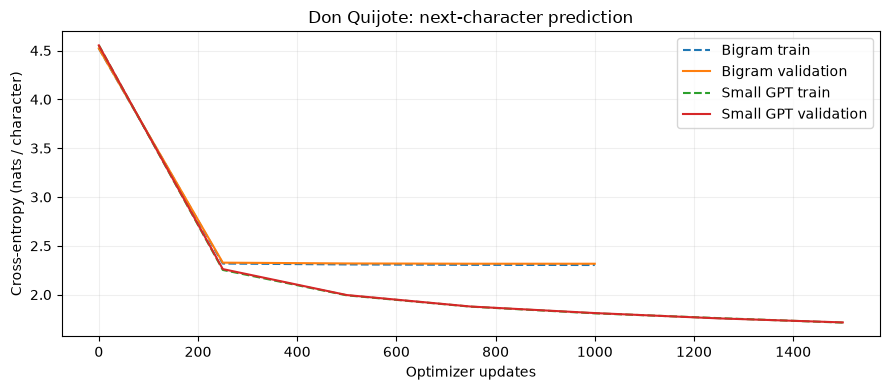

In [11]:
torch.manual_seed(SEED)
gpt_history = train_model(model, config['max_iters'], config['learning_rate'])

bigram_metrics = bigram_history[-1]
gpt_metrics = gpt_history[-1]
print('\nModel       Train loss   Val loss   Val perplexity')
for name, metrics in [('Bigram', bigram_metrics), ('Small GPT', gpt_metrics)]:
    print(f"{name:<11} {metrics['train']:>10.4f} {metrics['val']:>10.4f} {math.exp(metrics['val']):>16.2f}")
print(f"Validation loss improvement (bigram minus GPT): {bigram_metrics['val'] - gpt_metrics['val']:.4f} nats/character")

fig, ax = plt.subplots(figsize=(9, 4))
for history, name in [(bigram_history, 'Bigram'), (gpt_history, 'Small GPT')]:
    steps = [row['step'] for row in history]
    ax.plot(steps, [row['train'] for row in history], '--', label=f'{name} train')
    ax.plot(steps, [row['val'] for row in history], label=f'{name} validation')
ax.set(xlabel='Optimizer updates', ylabel='Cross-entropy (nats / character)', title='Don Quijote: next-character prediction')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(output_dir / 'loss_curve.png', dpi=160)
plt.show()


## 9. Generate new Spanish-style text

The prompt initializes the context. We sample one character, append it, and repeat. For prompts longer than the context window, only the last `block_size` characters inform the next prediction.

Lower `temperature` concentrates probability on likely characters; higher values increase variation and errors. `top_k` optionally limits sampling to the most likely characters. This model is trained only on one book and is too small for reliable facts, dialogue, or long-range story structure. Generated text is a sample, not a quotation from Cervantes.


In [12]:
prompt = 'En un lugar de la Mancha'
torch.manual_seed(SEED)
gpt_sample = generate(model, prompt, max_new_tokens=600, temperature=0.8)
print('SMALL GPT SAMPLE (prompt included):\n')
print(gpt_sample)
(output_dir / 'generated_don_quijote.txt').write_text(gpt_sample, encoding='utf-8')


SMALL GPT SAMPLE (prompt included):

En un lugar de la Mancha, puesto, y señor la peber aquella.

— Ya dagaña, mentre con cuarrced, será más sobían el a menero, y que tenía, que
simir de tenita, puesto de la cuando, la don Quijote despantura, y ninta
caballero, aquiero a en por la cuelura, sin conodo esfagunta confiallo; la ade que no muestra conto, sen
el ma Respillica y estan tuento catando milla que hay decir a allquello su en para
de le la y por que contine la en las diciendos entre en goberna de la

cuelta lo cosabazo ensu hay de las tadan desdentes los una unos ver adel quierrida ni
desentoza aquellas, a si quello altende de casando de todo, que s


## 10. Save and reload the model

Save learned weights together with the architecture settings and exact character vocabulary. Rebuilding a different vocabulary would silently change the meaning of token IDs. The checkpoint is for inference; it does not store optimizer state for exact training resumption. The original corpus hash records which download was used.


In [13]:
import json

checkpoint_path = output_dir / 'don_quijote_gpt.pt'
torch.save({
    'model_state': {name: tensor.detach().cpu() for name, tensor in model.state_dict().items()},
    'config': config,
    'chars': chars,
    'seed': SEED,
    'corpus_url': CORPUS_URL,
    'corpus_sha256': corpus_sha256,
    'bigram_history': bigram_history,
    'gpt_history': gpt_history,
}, checkpoint_path)
(output_dir / 'training_metrics.json').write_text(json.dumps({
    'config': config, 'corpus_sha256': corpus_sha256,
    'bigram': bigram_history, 'gpt': gpt_history,
}, indent=2), encoding='utf-8')

saved = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
assert saved['chars'] == chars
reloaded = GPTLanguageModel(len(saved['chars']), saved['config']).to(device)
reloaded.load_state_dict(saved['model_state'])
model.eval()
reloaded.eval()
with torch.no_grad():
    expected, _ = model(x[:1])
    actual, _ = reloaded(x[:1])
assert torch.allclose(expected, actual, atol=1e-5, rtol=1e-5)
print('Passed: saved and reloaded models return matching logits.')
print('Checkpoint:', checkpoint_path)
print('Sample:', output_dir / 'generated_don_quijote.txt')
print('Curve:', output_dir / 'loss_curve.png')


Passed: saved and reloaded models return matching logits.
Checkpoint: /Users/sovinbirla/UChicago/Generative AI/Week 4/don_quijote_outputs/don_quijote_gpt.pt
Sample: /Users/sovinbirla/UChicago/Generative AI/Week 4/don_quijote_outputs/generated_don_quijote.txt
Curve: /Users/sovinbirla/UChicago/Generative AI/Week 4/don_quijote_outputs/loss_curve.png


<!-- ## 11. Interpret the experiment

Use the executed table, curves, and samples to answer:

1. How far below `ln(vocab_size)` did each validation loss fall? Does GPT beat the bigram baseline?
2. Which Spanish-looking patterns appear in the GPT sample? Which words or sentences still fail?
3. Do training and validation loss decrease together? A widening gap suggests overfitting.
4. Why do we mask scores before softmax rather than simply zeroing probabilities afterward? What would happen if the model could read the target character?

**Try one change at a time:** increase `block_size` from 64 to 128, train for more updates, or compare temperatures 0.5, 0.8, and 1.2. Recreate and retrain models after changing the architecture or training configuration. A longer context raises attention memory/computation roughly quadratically in sequence length; coherent long prose is not guaranteed by increasing one setting.

For a fair architecture comparison, keep the data split and tokenizer fixed. Both models here use the same corpus and evaluation windows, but different learning rates and update counts; this is a teaching baseline comparison, not a controlled compute-budget study. -->


## Results from the executed run

The 115,676-parameter GPT reached **1.7157 validation loss**, compared with **2.3165** for the bigram model. Validation perplexity fell from **10.14 to 5.56** on the same sampled windows. GPT therefore assigned higher probabilities to held-out next characters.

Training loss (1.7135) and validation loss (1.7157) stayed close after 1,500 updates. The sample contains recognizable Spanish patterns alongside misspellings and broken sentences; this small model does not yet produce reliable prose.

All code cells ran in order on CPU in one Python process. Tokenization, shifted targets, causal attention, output shapes, finite losses, and matching saved/reloaded logits passed their checks. The plot is embedded above. Model weights, generated text, the loss curve, and training metrics are saved in `don_quijote_outputs/`.
